# 04 – AutoML pipeline v0.1

**ML Project – Early Detection of Students at Risk of Dropout** · Week 2

Module owner: **Axel Warot** · Group **AALT** (DIA4): Léo Chen, Adam Gaabi, Timéo Brajon, Axel Warot

In [1]:
import sys,warnings
warnings.filterwarnings("ignore")
sys.path.insert(0,"../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from features import *
pd.set_option("display.width",160)
pd.set_option("display.max_columns",40)
import time
from scipy.stats import loguniform,randint
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest,f_classif,SelectFromModel
from sklearn.model_selection import StratifiedKFold,RepeatedStratifiedKFold,RandomizedSearchCV,cross_validate
from sklearn.metrics import make_scorer,recall_score
tr=pd.read_csv("../data/processed/train.csv")

## 1. Search space
One pipeline = **preprocessing → feature selection → model**. A randomised search explores together:
- feature selection: none, ANOVA top-k (k = 20 / 40), ℓ1 logistic regression;
- 6 standard models: logistic regression, decision tree, k-NN, SVM (RBF), Gaussian naive Bayes, random forest;
- their main hyperparameters, including class weights.

Search on scenario B (main use case), 90 configurations × 5 folds, scored by macro-F1.

In [2]:
s="B_semester1";X,y=split_xy(tr,s)
pipe=Pipeline([("prep",preprocessor(s)),("sel","passthrough"),("clf",LogisticRegression())])
SEL=["passthrough",SelectKBest(f_classif,k=20),SelectKBest(f_classif,k=40),SelectFromModel(LogisticRegression(penalty="l1",solver="saga",C=0.1,max_iter=2000,class_weight="balanced"))]
CW=[None,"balanced"]
space=[
{"sel":SEL,"clf":[LogisticRegression(max_iter=3000)],"clf__C":loguniform(1e-3,1e2),"clf__class_weight":CW},
{"sel":SEL,"clf":[DecisionTreeClassifier(random_state=SEED)],"clf__max_depth":randint(2,15),"clf__min_samples_leaf":randint(1,50),"clf__class_weight":CW},
{"sel":SEL,"clf":[KNeighborsClassifier()],"clf__n_neighbors":randint(3,60),"clf__weights":["uniform","distance"]},
{"sel":SEL,"clf":[SVC(random_state=SEED)],"clf__C":loguniform(1e-2,1e2),"clf__gamma":loguniform(1e-4,1e-1),"clf__class_weight":CW},
{"sel":SEL,"clf":[GaussianNB()],"clf__var_smoothing":loguniform(1e-10,1e-2)},
{"sel":SEL,"clf":[RandomForestClassifier(random_state=SEED,n_jobs=1)],"clf__n_estimators":randint(100,400),"clf__max_depth":[None,8,15],"clf__min_samples_leaf":randint(1,10),"clf__class_weight":CW+["balanced_subsample"]}]
t=time.perf_counter()
search=RandomizedSearchCV(pipe,space,n_iter=90,scoring={"macro_f1":"f1_macro","bal_acc":"balanced_accuracy"},refit="macro_f1",cv=StratifiedKFold(5,shuffle=True,random_state=SEED),n_jobs=-1,random_state=SEED,error_score="raise").fit(X,y)
print(f"Search time: {time.perf_counter()-t:.0f} s")

Search time: 154 s


## 2. Results by model family

In [3]:
res=pd.DataFrame(search.cv_results_)
res["model"]=res["param_clf"].astype(str).str.split("(").str[0]
res["selection"]=res["param_sel"].map(lambda v:"none" if v=="passthrough" else ("L1" if "SelectFromModel" in str(v) else f"top-{v.k}"))
res["params"]=res["params"].map(lambda p:", ".join(f"{k.split('__')[-1]}={v:.3g}" if isinstance(v,float) else f"{k.split('__')[-1]}={v}" for k,v in p.items() if k.startswith("clf__")))
best=res.sort_values("mean_test_macro_f1",ascending=False).groupby("model").head(1)
best=best[["model","selection","params","mean_test_macro_f1","std_test_macro_f1","mean_test_bal_acc","mean_fit_time"]].reset_index(drop=True)
best.to_csv("../results/automl_v01_best_per_model.csv",index=False)
best.round(3)

,model,selection,params,mean_test_macro_f1,std_test_macro_f1,mean_test_bal_acc,mean_fit_time
0,RandomForestClassifier,none,"class_weight=balanced_subsample, max_depth=15,...",0.689,0.022,0.688,0.816
1,SVC,L1,"C=39.3, class_weight=balanced, gamma=0.00552",0.687,0.022,0.695,1.875
2,LogisticRegression,none,"C=0.767, class_weight=balanced",0.685,0.020,0.693,0.114
3,DecisionTreeClassifier,top-40,"class_weight=balanced, max_depth=9, min_sample...",0.643,0.017,0.652,0.027
4,KNeighborsClassifier,top-20,"n_neighbors=22, weights=distance",0.621,0.013,0.613,0.025
5,GaussianNB,top-20,var_smoothing=0.00257,0.598,0.017,0.595,0.019


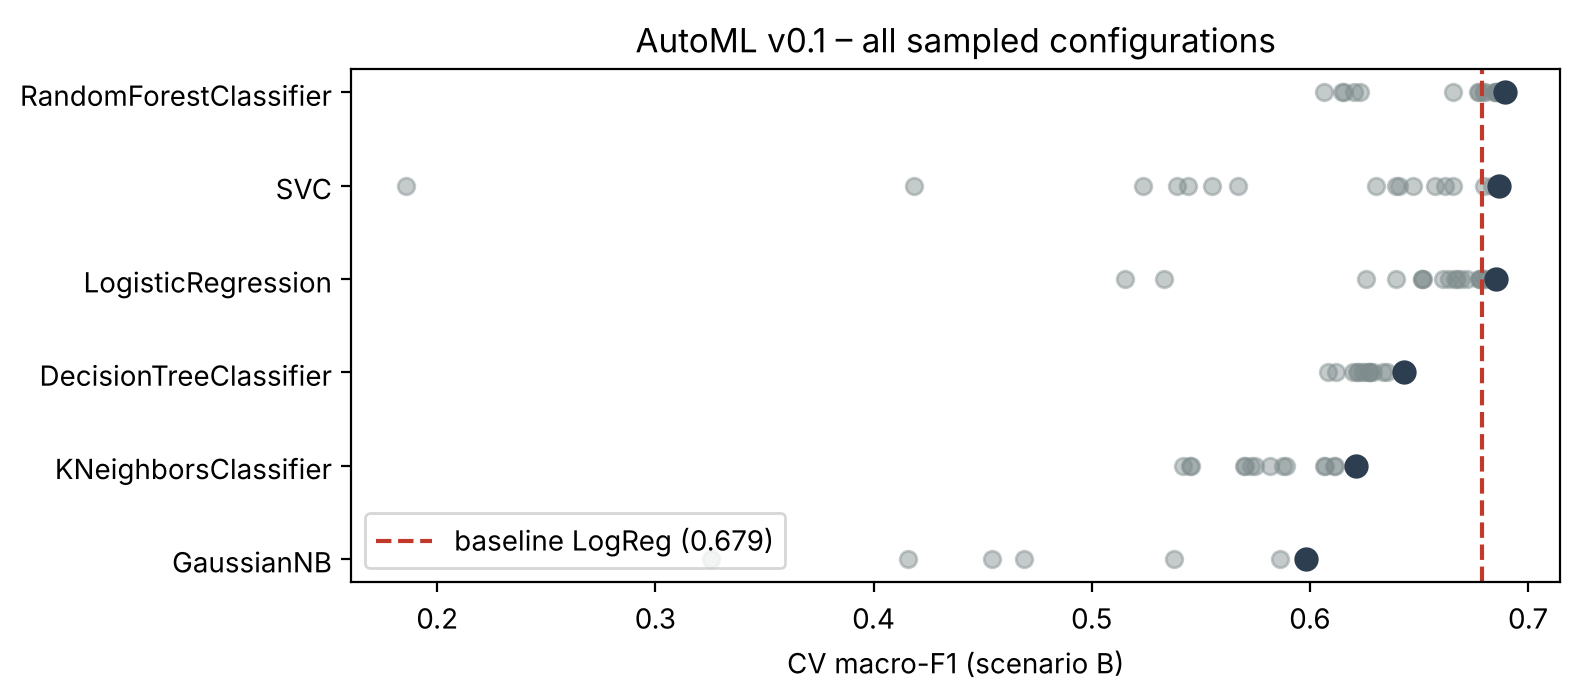

Best configuration: {'clf': RandomForestClassifier(n_jobs=1, random_state=42), 'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 15, 'clf__min_samples_leaf': 4, 'clf__n_estimators': 230, 'sel': 'passthrough'}


In [4]:
fig,ax=plt.subplots(figsize=(8,3.6))
order=best["model"].tolist()
for i,m in enumerate(order):
    v=res.loc[res.model==m,"mean_test_macro_f1"]
    ax.scatter(v,[i]*len(v),alpha=.45,color="#7f8c8d")
    ax.scatter(v.max(),i,color="#2c3e50",s=60)
b=pd.read_csv("../results/baseline_cv.csv").query("model=='LogReg balanced' and scenario=='B_semester1'")["macro_f1"].iloc[0]
ax.axvline(b,ls="--",color="#c0392b",label=f"baseline LogReg ({b:.3f})")
ax.set_yticks(range(len(order)),order);ax.invert_yaxis();ax.set_xlabel("CV macro-F1 (scenario B)");ax.legend(loc="lower left")
ax.set_title("AutoML v0.1 – all sampled configurations")
plt.tight_layout();plt.savefig("../report/figures/automl.png",dpi=150);plt.show()
print("Best configuration:",search.best_params_)

## 3. Best pipeline across scenarios
The best configuration found on scenario B is re-evaluated with the same repeated CV as the baseline (5 × 3), for the three scenarios.

In [5]:
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED)
base=pd.read_csv("../results/baseline_cv.csv").query("model=='LogReg balanced'").set_index("scenario")
rows=[]
for sc in SCENARIOS:
    Xs,ys=split_xy(tr,sc)
    p=Pipeline([("prep",preprocessor(sc)),("sel",search.best_estimator_.named_steps["sel"]),("clf",search.best_estimator_.named_steps["clf"])])
    r=cross_validate(p,Xs,ys,cv=cv,scoring={"macro_f1":"f1_macro","bal_acc":"balanced_accuracy","dropout_recall":make_scorer(recall_score,labels=["Dropout"],average="macro")},n_jobs=-1)
    rows.append({"scenario":sc,"baseline macro-F1":base.loc[sc,"macro_f1"],"AutoML macro-F1":r["test_macro_f1"].mean(),"AutoML std":r["test_macro_f1"].std(),"AutoML bal. acc.":r["test_bal_acc"].mean(),"AutoML dropout recall":r["test_dropout_recall"].mean()})
cmp=pd.DataFrame(rows).assign(gain=lambda t:t["AutoML macro-F1"]-t["baseline macro-F1"])
cmp.to_csv("../results/automl_v01_vs_baseline.csv",index=False)
cmp.round(3)

,scenario,baseline macro-F1,AutoML macro-F1,AutoML std,AutoML bal. acc.,AutoML dropout recall,gain
0,A_enrollment,0.573,0.584,0.015,0.587,0.631,0.011
1,B_semester1,0.679,0.691,0.018,0.690,0.724,0.012
2,C_all,0.715,0.725,0.018,0.726,0.743,0.010


## Takeaways (v0.1)
- The search is automatic and reproducible, but the best models are only slightly above the logistic regression baseline: on this tabular data the baseline is already strong.
- Scores on the configuration chosen by the search are slightly optimistic (selection on the same folds). Week 3: nested CV for the final comparison.
- Limitations to address in week 3: *Enrolled* class, decision threshold for dropout recall, boosting / ensembles, cohort-based validation.